# Modelación como Movimiento Browniano Geométrico y valoración de opciones europeas

**Proyecto Final — Cálculo Estocástico (Freddy H. Marín, Universidad EAFIT)**

Este notebook tiene **dos partes**:

1. **Identificación, estimación, simulación y pronóstico bajo el MBG**
2. **Pronóstico fuera de muestra y valoración de opciones Call europeas** con cuatro métodos
   (Black-Scholes, Monte Carlo, árbol binomial CRR y diferencias finitas), que se conserva
   intacta respecto de la versión anterior del proyecto.

El activo analizado es la tasa de cambio CAD/USD (`DEXCAUS.csv`) **

**Modelo.** $dS_t=\mu S_t\,dt+\sigma S_t\,dW_t$. En la **primera parte** (pronóstico
in-sample) se usa el esquema **Euler–Maruyama**, como en el notebook de referencia:
$$S_{t+\Delta t}=S_t+\hat\mu S_t\,\Delta t+\hat\sigma S_t\sqrt{\Delta t}\,\varepsilon,\qquad \varepsilon\sim N(0,1).$$
En la **segunda parte** (out-of-sample y valoración) se usa la **solución exacta** del MBG
bajo medida riesgo-neutral, como recomiendan los apuntes para la valoración de opciones.

### Origen de los datos **

El conjunto de datos corresponde a la tasa de cambio del dólar canadiense frente al
dólar estadounidense (**DEXCAUS**, \(S_t\)) y fue consultado del **Banco de la Reserva
Federal de Saint Louis** (Missouri, Estados Unidos), disponible para descarga en
[FRED](https://fred.stlouisfed.org/). La serie cubre el periodo de **noviembre de 2025 a
noviembre de 2026**.

El archivo contiene 261 registros en ese periodo, de los cuales **250 corresponden a
cotizaciones efectivas** y los 11 restantes a días festivos o no hábiles en los mercados,
que se descartan del análisis (quedan como `NaN` al cargar la serie y se eliminan). El
estudio trabaja, por tanto, sobre 250 observaciones válidas, por encima del mínimo exigido
de 250.

La serie presenta fases diferenciadas: un descenso desde niveles cercanos a 1,41 hasta un
mínimo de aproximadamente 1,3518 en febrero de 2026, seguido de una recuperación con alta
volatilidad y estabilización, con máximos locales alrededor de 1,4237 a mediados de año y
un pico cercano a 1,4273 en octubre de 2026.



## 1. Librerías

In [32]:
# pip install pandas numpy scipy matplotlib seaborn statsmodels
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox, normal_ad, lilliefors

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 13, "axes.labelsize": 11,
                     "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.6f}".format


## 2. Parámetros y funciones configurables
**Todo lo modificable está aquí.** El notebook está fijado a un único conjunto de datos,
`DEXCAUS.csv` (tasa de cambio CAD/USD).

### 2.1  PARÁMETROS MODIFICABLES

In [33]:
# ---- Datos ----
DATA_DIR = "data"                 # carpeta con los CSV
# El análisis se realiza exclusivamente sobre la serie DEXCAUS (tasa CAD/USD).
CSV_NAME = "DEXCAUS.csv"
CSV_PATH = os.path.join(DATA_DIR, CSV_NAME)
DATE_CANDIDATES = ["date", "observation_date", "Date", "Fecha"]  # posibles nombres de la col. de fecha
# ---- Convenciones temporales ----
PPY = 252                          # periodos por año (datos diarios de mercado)
dt = 1 / PPY                       # paso temporal en años
ALPHA = 0.05                       # nivel de significancia de las pruebas
alpha = ALPHA                      # alias usado en los diagnósticos estilo IEP
# ---- Simulación / pronóstico ----
N_SIM = 10_000                     # simulaciones (in-sample y out-of-sample) — exigido por el enunciado
k = N_SIM                          # alias estilo IEP: nº de trayectorias del pronóstico
N_PATHS_C5 = 5_000                 # trayectorias para el chequeo visual auxiliar (C5)
SEED = 2026                        # semilla global de reproducibilidad
semilla = SEED                     # alias estilo IEP
n_plot = 150                       # trayectorias dibujadas (solo afecta las figuras, no los cálculos)
# ---- Parámetros de los diagnósticos estilo IEP ----
lags_pacf = 20                     # retardos de las PACF
q_arch = 5                         # retardos del test ARCH de Engle
q_lbq = 5                          # retardos del test Ljung-Box
# ---- Valoración de opciones (parámetros fijos del enunciado) ----
r_free = 0.05                      # tasa libre de riesgo (ENUNCIADO: r = 0.05)
q_yield = 0.00                     # rendimiento continuo (0 = Black-Scholes clásico; >0 = Garman-Kohlhagen)
T_LIST = [1, 1/2, 1/3, 1/4]        # vencimientos (años)
PCTS = [10, 25, 50, 75, 90]        # percentiles de S_T simulado -> 5 strikes por T
N_BIN = 1000                       # pasos del árbol binomial CRR
NH_FD = 300                        # nodos a cada lado de S0 en la malla de diferencias finitas
PRICE_DECIMALS = 4                 # redondeo de precios/strikes (recomendación del profesor)
# El enunciado solo requiere opciones Call europeas.
OPTION_KINDS = ["call"]
np.random.seed(42)                 # para las celdas que usan el estado global de numpy

### 2.2  FUNCIONES AUXILIARES

#### 2.2.1 CARGA (sistema propio del proyecto)

In [34]:
def load_series(csv_path, date_candidates=DATE_CANDIDATES):
    """Lee un CSV date,<activo>, detecta la columna de fecha y extrae ASSET_NAME.

    Devuelve (S, asset_name) donde S es una Serie de precios indexada por fecha.
    """
    raw = pd.read_csv(csv_path)
    date_col = next((c for c in raw.columns if c in date_candidates), raw.columns[0])
    asset_col = next(c for c in raw.columns if c != date_col)
    raw[date_col] = pd.to_datetime(raw[date_col])
    raw[asset_col] = pd.to_numeric(raw[asset_col], errors="coerce")  # feriados/celdas vacías -> NaN
    s = (raw.set_index(date_col)[asset_col]
            .sort_index()
            .dropna())
    s.index.name = "Date"
    s.name = asset_col
    return s, asset_col


#### 2.2.2  FUNCIONES AUXILIARES — DIAGNÓSTICOS Y PRONÓSTICO (estilo IEP)
Traducción de fractalvol.m (dimensión fractal) y genhurst.m (exponente de Hurst generalizado, T. Aste 2013), más utilidades (MAPE, cuantiles tipo MATLAB y estadísticos descriptivos).

In [35]:
def _percentil_matlab(x, p):
    """Percentiles con la convención de MATLAB (prctile/iqr/quantile): método 'hazen'."""
    try:
        return np.percentile(x, p, method="hazen")
    except TypeError:               # versiones antiguas de numpy
        return np.percentile(x, p)


def quantil_matlab(a, probs, axis=0):
    """Equivalente a quantile(a, probs) de MATLAB."""
    try:
        return np.quantile(a, probs, axis=axis, method="hazen")
    except TypeError:
        return np.quantile(a, probs, axis=axis)


def fractalvol(data):
    """
    [dimension, standard_dev] = fractalvol(data)

    Dimensión fractal de una caminata aleatoria 1D (data) por conteo de cajas, incrustando
    la serie en el cuadrado unitario (y = valores reescalados, x = índice/longitud).
    Devuelve la dimensión y la desviación estándar de la pendiente (teoría MCO).
    """
    data = np.asarray(data, dtype=float)
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    if data.shape[0] < data.shape[1]:
        data = data.T
    if data.shape[1] == 1:
        data = np.column_stack([np.arange(1, len(data) + 1), data[:, 0]])
    data = data[np.argsort(data[:, 0], kind="stable")]

    max1, min1 = data[:, 0].max(), data[:, 0].min()
    max2, min2 = data[:, 1].max(), data[:, 1].min()

    normdata = data.copy()
    normdata[:, 0] = (normdata[:, 0] - min1) / (max1 - min1)
    normdata[:, 1] = (normdata[:, 1] - min2) / (max2 - min2)
    xs, ys = normdata[:, 0], normdata[:, 1]

    minwidth = np.min(np.diff(xs))
    minwidth = np.log2(minwidth)
    minwidth = int(abs(np.ceil(minwidth))) - 1
    if minwidth < 3:
        raise ValueError("Serie demasiado corta para estimar la dimensión fractal.")

    n = np.zeros(minwidth)
    for j in range(1, minwidth + 1):
        width = 2.0 ** -j
        xaxis_pos = 0.0
        boxcount = 0
        while xaxis_pos < 1:
            lo = np.searchsorted(xs, xaxis_pos, side="left")
            hi = np.searchsorted(xs, xaxis_pos + width, side="left")
            if 1 - xaxis_pos == width:      # última columna: incluye el último punto (x = 1)
                hi = len(xs)
            vertical_column = ys[lo:hi]
            if len(vertical_column) == 1:
                boxcount += 1
            elif len(vertical_column) > 1:
                rawcount = (vertical_column.max() - vertical_column.min()) / width
                rawcount = rawcount + np.fmod(vertical_column.min(), width)   # rem() de MATLAB
                boxcount += int(np.ceil(rawcount))
            xaxis_pos += width
        n[j - 1] = boxcount

    r_ = 2.0 ** -np.arange(1, minwidth + 1)
    s = -np.gradient(np.log(n)) / np.gradient(np.log(r_))
    IQR = _percentil_matlab(s, 75) - _percentil_matlab(s, 25)
    indx2 = np.abs(s - np.median(s)) > IQR / 2
    x2 = np.log(r_)[~indx2]
    y2 = np.log(n)[~indx2]

    X_ = np.column_stack([np.ones_like(x2), x2])
    beta = np.linalg.pinv(X_) @ y2
    C = np.linalg.pinv(X_.T @ X_)
    e = y2 - X_ @ beta
    sigma = np.sqrt((e @ e) * C)

    dimension = -beta[1]
    standard_dev = sigma[1, 1]
    return dimension, standard_dev


def genhurst(S, q=1, maxT=19):
    """
    mH, sH = genhurst(S, q=1, maxT=19)

    Exponente de Hurst generalizado H(q) a partir del escalamiento de los q-momentos
    renormalizados: <|x(t+r)-x(t)|^q> / <x(t)^q> ~ r^[q H(q)].
    Devuelve H(q) y su desviación estándar sH(q) (escalares si q es escalar).
    """
    S = np.asarray(S, dtype=float).ravel()
    q_escalar = np.isscalar(q)
    q = np.atleast_1d(np.asarray(q, dtype=float))
    L = len(S)
    lq = len(q)
    if L < max(maxT * 4, 60):
        warnings.warn("Data serie very short!")

    H = []
    for Tmax in range(5, maxT + 1):
        x = np.arange(1, Tmax + 1)
        mcord = np.zeros((Tmax, lq))
        for tt in range(1, Tmax + 1):
            idx = np.arange(tt + 1, L + 1, tt)                  # (tt+1):tt:L
            dV = S[idx - 1] - S[idx - tt - 1]
            idx2 = np.arange(tt + 1, L + tt + 1, tt)            # (tt+1):tt:(L+tt)
            VV = S[idx2 - tt - 1]
            N_ = len(dV) + 1
            X_ = np.arange(1, N_ + 1)
            Y_ = VV
            mx = X_.sum() / N_
            SSxx = (X_ ** 2).sum() - N_ * mx ** 2
            my = Y_.sum() / N_
            SSxy = (X_ * Y_).sum() - N_ * mx * my
            cc1 = SSxy / SSxx
            cc2 = my - cc1 * mx
            ddVd = dV - cc1
            VVVd = VV - cc1 * X_ - cc2
            for qq in range(lq):
                mcord[tt - 1, qq] = np.mean(np.abs(ddVd) ** q[qq]) / np.mean(np.abs(VVVd) ** q[qq])

        lx = np.log10(x)
        mx = lx.mean()
        SSxx = (lx ** 2).sum() - Tmax * mx ** 2
        fila = np.zeros(lq)
        for qq in range(lq):
            lm = np.log10(mcord[:, qq])
            my = lm.mean()
            SSxy = (lx * lm).sum() - Tmax * mx * my
            fila[qq] = SSxy / SSxx
        H.append(fila)

    H = np.array(H)
    mH = H.mean(axis=0) / q
    sH = H.std(axis=0, ddof=1) / q
    if q_escalar:
        return float(mH[0]), float(sH[0])
    return mH, sH


def mape(real, pron):
    """MAPE en %. 'pron' puede ser (N,) o (k, N): devuelve un valor por fila."""
    real = np.asarray(real, dtype=float)
    pron = np.asarray(pron, dtype=float)
    return np.mean(np.abs((real - pron) / real), axis=-1) * 100


def descripcion_estadistica(v):
    """[min max media mediana moda var desv curtosis asimetría] como EstadX de MATLAB."""
    v = np.asarray(v, dtype=float)
    vals, cuentas = np.unique(v, return_counts=True)
    moda = vals[np.argmax(cuentas)]          # en empates, el menor (como mode de MATLAB)
    return pd.Series({
        "Mínimo": v.min(),
        "Máximo": v.max(),
        "Media": v.mean(),
        "Mediana": np.median(v),
        "Moda": moda,
        "Varianza": v.var(ddof=1),
        "Desv. estándar": v.std(ddof=1),
        "Curtosis": stats.kurtosis(v, fisher=False),   # Pearson (normal = 3), como MATLAB
        "Asimetría": stats.skew(v),
    })


def formato_fechas(ax):
    """Eje x con fechas legibles."""
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))


#### 2.2.3  FUNCIONES AUXILIARES — VALORACIÓN DE OPCIONES (segunda parte, sin cambios)

In [36]:
def bs_price(S0, K, T, r, q, sig, kind):
    """Black-Scholes cerrado (q=0 -> BS clásico; q>0 -> Garman-Kohlhagen)."""
    d1 = (np.log(S0 / K) + (r - q + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if kind == "call":
        return S0 * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(-r * T) * stats.norm.cdf(d2)
    return K * np.exp(-r * T) * stats.norm.cdf(-d2) - S0 * np.exp(-q * T) * stats.norm.cdf(-d1)

def mc_price(S0, K, T, r, q, sig, Zhalf, kind):
    """Monte Carlo riesgo-neutral con solución EXACTA del MBG + variables antitéticas.

    S_T = S0 * exp((r - q - sig^2/2) T + sig sqrt(T) Z).  Devuelve (precio, error estándar).
    """
    def payoff(Z):
        ST = S0 * np.exp((r - q - 0.5 * sig**2) * T + sig * np.sqrt(T) * Z)
        return np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    pair = 0.5 * (payoff(Zhalf) + payoff(-Zhalf)) * np.exp(-r * T)
    return pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair))

def binomial_crr(S0, K, T, r, q, sig, kind, N=N_BIN):
    """Árbol binomial Cox-Ross-Rubinstein con N pasos (inducción hacia atrás)."""
    dt_ = T / N; u = np.exp(sig * np.sqrt(dt_)); d = 1 / u
    p = (np.exp((r - q) * dt_) - d) / (u - d); disc = np.exp(-r * dt_)
    assert 0 < p < 1, "Probabilidad riesgo-neutral fuera de (0,1): reduzca dt_"
    j = np.arange(N + 1); ST = S0 * u**j * d**(N - j)
    V = np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    for _ in range(N):
        V = disc * (p * V[1:] + (1 - p) * V[:-1])
    return V[0]

def fd_explicit(S0, K, T, r, q, sig, kind, Nh=NH_FD, safety=0.9):
    """Diferencias finitas explícitas sobre la EDP de BS en x = ln S.

    V_tau = 1/2 sig^2 V_xx + (r - q - sig^2/2) V_x - r V, con dt <= dx^2/sig^2.
    Devuelve (precio, numero_de_pasos_temporales).
    """
    nu = r - q - 0.5 * sig**2
    L = 6 * sig * np.sqrt(T) + abs(nu) * T                # semiancho del dominio en log-precio
    dx = L / Nh
    Nt = int(np.ceil(T / (safety * dx**2 / sig**2))); dtau = T / Nt
    a = dtau * (0.5 * sig**2 / dx**2 - 0.5 * nu / dx)     # coef. de V_{j-1}
    b = 1 - dtau * (sig**2 / dx**2 + r)                   # coef. de V_j
    c = dtau * (0.5 * sig**2 / dx**2 + 0.5 * nu / dx)     # coef. de V_{j+1}
    assert min(a, b, c) >= 0, "Esquema explícito inestable: aumente Nh o reduzca dt"
    Sg = S0 * np.exp(dx * np.arange(-Nh, Nh + 1))         # S0 es nodo exacto (índice Nh)
    V = np.maximum(Sg - K, 0.0) if kind == "call" else np.maximum(K - Sg, 0.0)
    for kk in range(1, Nt + 1):
        tau = kk * dtau
        Vn = np.empty_like(V)
        Vn[1:-1] = a * V[:-2] + b * V[1:-1] + c * V[2:]
        if kind == "call":
            Vn[0], Vn[-1] = 0.0, Sg[-1] * np.exp(-q * tau) - K * np.exp(-r * tau)
        else:
            Vn[0], Vn[-1] = K * np.exp(-r * tau) - Sg[0] * np.exp(-q * tau), 0.0
        V = Vn
    return V[Nh], Nt


## 3. Carga y limpieza de datos

Se usa el cargador propio del proyecto (`load_series`), que detecta la columna de fecha,
extrae `ASSET_NAME` del encabezado de la segunda columna y devuelve la serie de precios
`S` indexada por fecha. A partir de `S` se definen los objetos estilo IEP:

- `dates`: fechas reales (solo para los ejes de los gráficos);
- `X`: array numérico con los precios (único insumo de los cálculos estocásticos);
- `N = len(X)`.

Los precios se redondean a `PRICE_DECIMALS` (recomendación del profesor).

In [37]:
S, ASSET_NAME = load_series(CSV_PATH)
S = S.round(PRICE_DECIMALS)                 # precios redondeados

# --- Objetos estilo IEP (la metodología de análisis trabaja sobre X y dates) ---
dates = S.index.to_series().reset_index(drop=True)   # fechas, solo para graficar
X = S.to_numpy(dtype=float)                           # serie del activo subyacente
N = len(X)

if np.any(X <= 0):
    raise ValueError("El MBG requiere valores estrictamente positivos (se usan cocientes y logaritmos).")
assert N >= 250, "El enunciado exige al menos 250 observaciones."

print(f"Activo analizado (ASSET_NAME): {ASSET_NAME}")
print(f"Archivo: {CSV_PATH}")
print(f"Observaciones: {N}  |  Desde {dates.iloc[0].date()} hasta {dates.iloc[-1].date()}")
print(f"dt = {dt:.6f}  (≈ 1/{1/dt:.0f})  |  k = {k} trayectorias  |  semilla = {semilla}")
S.tail(3).to_frame(ASSET_NAME)


Activo analizado (ASSET_NAME): DEXCAUS
Archivo: data\DEXCAUS.csv
Observaciones: 250  |  Desde 2025-11-07 hasta 2026-11-06
dt = 0.003968  (≈ 1/252)  |  k = 10000 trayectorias  |  semilla = 2026


,DEXCAUS
Date,
2026-11-04,1.397300
2026-11-05,1.398000
2026-11-06,1.410600


## 4. Análisis cuantitativo de la serie

### Gráfica del activo

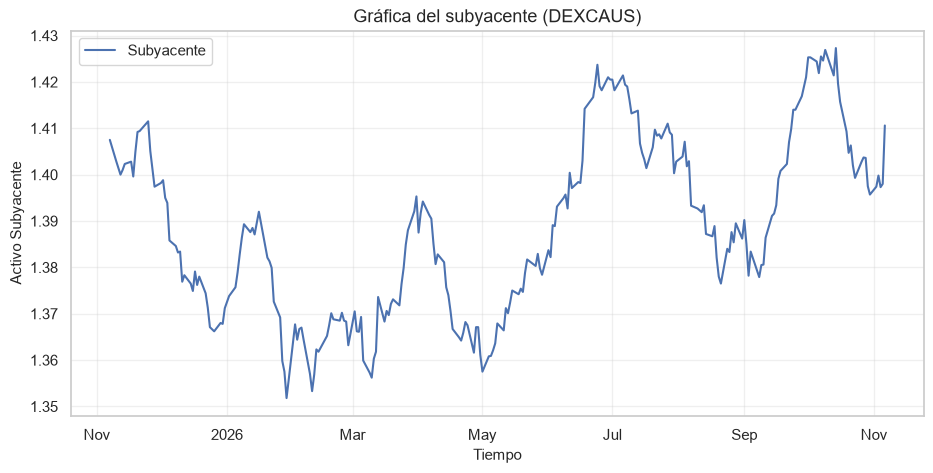

In [38]:
fig, ax = plt.subplots()
ax.plot(dates, X, label="Subyacente")
ax.set_xlabel("Tiempo")
ax.set_ylabel("Activo Subyacente")
ax.set_title(f"Gráfica del subyacente ({ASSET_NAME})")
ax.legend()
formato_fechas(ax)
plt.show()


### Paso 0: Descripción estadística del activo

,Mínimo,Máximo,Media,Mediana,Moda,Varianza,Desv. estándar,Curtosis,Asimetría
Subyacente,1.351800,1.427300,1.388349,1.387150,1.367100,0.000359,0.018949,2.033949,0.195183


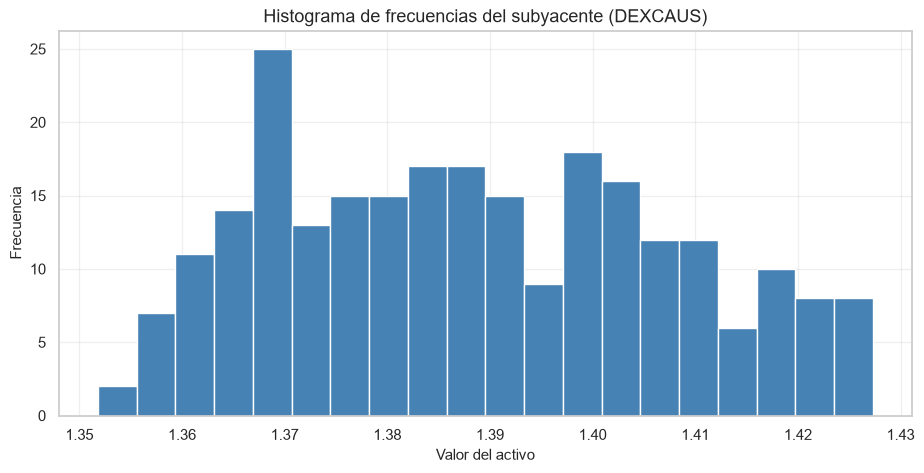

In [39]:
EstadX = descripcion_estadistica(X).to_frame("Subyacente").T
display(EstadX)

fig, ax = plt.subplots()
ax.hist(X, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Valor del activo")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Histograma de frecuencias del subyacente ({ASSET_NAME})")
plt.show()


#### Análisis: descripción estadística de DEXCAUS

Sobre las 250 observaciones (nov-2025 a nov-2026), la serie se mueve en un rango estrecho:
mínimo **1,3518**, máximo **1,4273** y media **1,3883** (desviación estándar 0,0189, apenas
un 1,4 % de la media). La mediana (1,3872) queda muy cerca de la media y la asimetría es
leve y positiva (0,20), con curtosis de 2,03 (por debajo de 3), lo que describe una
distribución de niveles poco concentrada en las colas. Estos estadísticos reflejan el perfil
típico de una tasa de cambio desarrollada (CAD/USD): variaciones acotadas y sin saltos
extremos en el periodo. El histograma no debe interpretarse como evidencia de normalidad del
proceso: el supuesto del MBG se verifica sobre los **retornos**, no sobre el nivel del precio.

### Paso 1: Autocorrelación parcial, dimensión fractal y exponente de Hurst

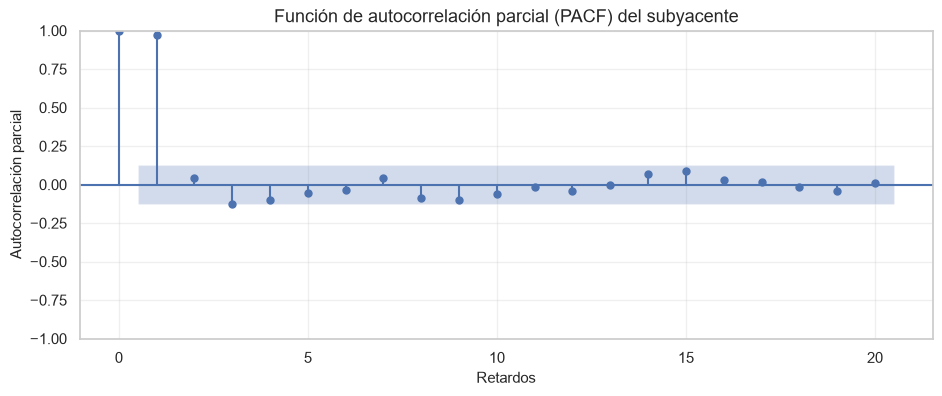

,Valor,Desv. estándar
Dimensión fractal (DF),1.150759,0.017872
Exponente de Hurst (EH),0.609134,0.008589
DF + EH,1.759893,NaN


Referencia: para un movimiento browniano estándar se espera DF + EH ≈ 2 (DF ≈ 1.5, EH ≈ 0.5).


In [40]:
fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(X, lags=lags_pacf, method="ywm", ax=ax)
ax.set_title("Función de autocorrelación parcial (PACF) del subyacente")
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()

DF, DF_sd = fractalvol(X)      # Dimensión fractal
EH, EH_sd = genhurst(X)        # Exponente de Hurst (q = 1)
S_fh = DF + EH

Z_fh = pd.DataFrame(
    {"Valor": [DF, EH, S_fh], "Desv. estándar": [DF_sd, EH_sd, np.nan]},
    index=["Dimensión fractal (DF)", "Exponente de Hurst (EH)", "DF + EH"],
)
display(Z_fh)
print("Referencia: para un movimiento browniano estándar se espera DF + EH ≈ 2 (DF ≈ 1.5, EH ≈ 0.5).")


#### Análisis: dimensión fractal y exponente de Hurst

Se obtiene una dimensión fractal **DF = 1,15** y un exponente de Hurst **EH = 0,61**, cuya
suma es **1,76**, próxima al valor de referencia 2 esperado para un movimiento browniano
(DF ≈ 1,5, EH ≈ 0,5). El Hurst ligeramente superior a 0,5 sugiere una persistencia débil, y
la PACF del nivel decae sin estructura periódica marcada. En conjunto, la serie no exhibe
memoria de largo plazo relevante que invalide el supuesto de incrementos independientes del
MBG; la desviación respecto de 2 es moderada y compatible con el ruido de una muestra de 250
puntos.

## 5. Análisis cuantitativo de los retornos instantáneos

### Paso 2: Análisis de los retornos instantáneos

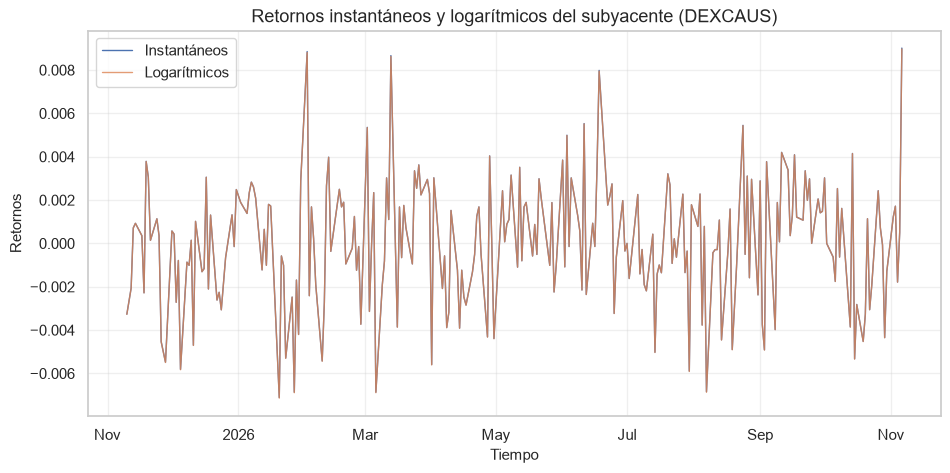

,Mínimo,Máximo,Media,Mediana,Moda,Varianza,Desv. estándar,Curtosis,Asimetría
Retornos,-0.007112,0.009013,0.000013,0.000000,0.000000,0.000008,0.002838,3.433843,0.017927


In [41]:
R = np.diff(X) / X[:-1]            # Retornos instantáneos (simples)
rl = np.log(X[1:] / X[:-1])        # Retornos logarítmicos
dates_r = dates.iloc[1:]           # fechas asociadas a los retornos

fig, ax = plt.subplots()
ax.plot(dates_r, R, label="Instantáneos", lw=1)
ax.plot(dates_r, rl, label="Logarítmicos", lw=1, alpha=0.8)
ax.set_xlabel("Tiempo")
ax.set_ylabel("Retornos")
ax.set_title(f"Retornos instantáneos y logarítmicos del subyacente ({ASSET_NAME})")
ax.legend()
formato_fechas(ax)
plt.show()

EstadR = descripcion_estadistica(R).to_frame("Retornos").T
display(EstadR)


#### Análisis: retornos instantáneos

Los retornos diarios de DEXCAUS tienen media prácticamente nula (**0,0013 %** diario) y
desviación estándar de **0,284 %**, con asimetría casi nula (0,02) y curtosis de **3,43**,
muy cercana al valor 3 de la normal (solo un leve exceso de colas). El rango va de −0,71 % a
+0,90 %, sin saltos atípicos pronunciados. Este comportamiento (centrado en cero, simétrico y
sin colas pesadas marcadas) es el que requiere el MBG para sus incrementos y anticipa que las
pruebas formales de normalidad no deberían rechazarse de forma sistemática.

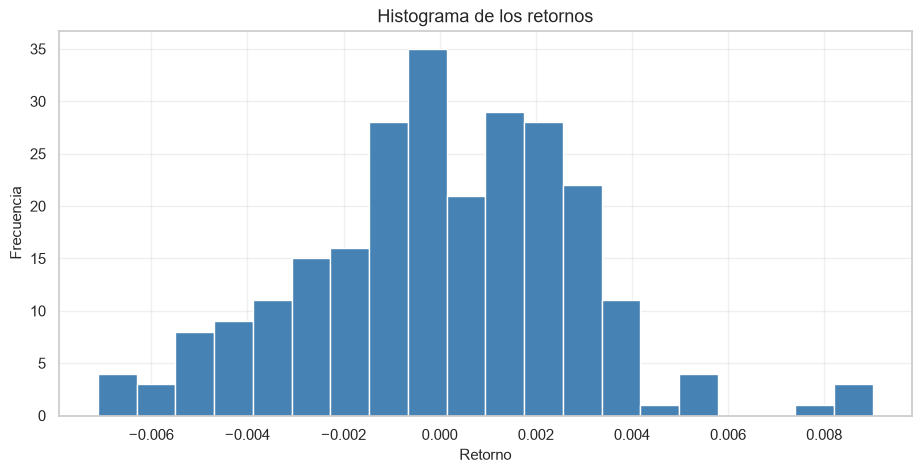

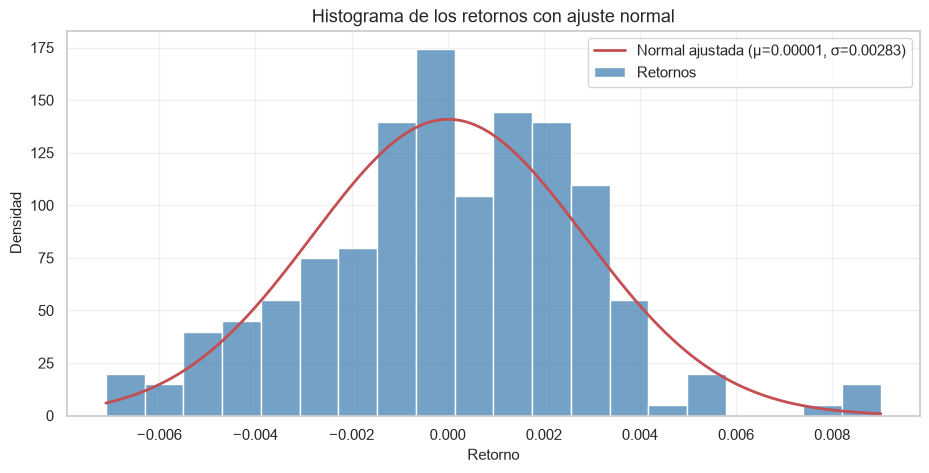

In [42]:
# Histograma de frecuencias de los retornos
fig, ax = plt.subplots()
ax.hist(R, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Retorno")
ax.set_ylabel("Frecuencia")
ax.set_title("Histograma de los retornos")
plt.show()

# Histograma con ajuste normal (equivalente a histfit)
mu_fit, sd_fit = stats.norm.fit(R)
xx = np.linspace(R.min(), R.max(), 400)
fig, ax = plt.subplots()
sns.histplot(R, bins=20, stat="density", color="steelblue", edgecolor="white", ax=ax, label="Retornos")
ax.plot(xx, stats.norm.pdf(xx, mu_fit, sd_fit), "r", lw=2,
        label=f"Normal ajustada (μ={mu_fit:.5f}, σ={sd_fit:.5f})")
ax.set_xlabel("Retorno")
ax.set_ylabel("Densidad")
ax.set_title("Histograma de los retornos con ajuste normal")
ax.legend()
plt.show()


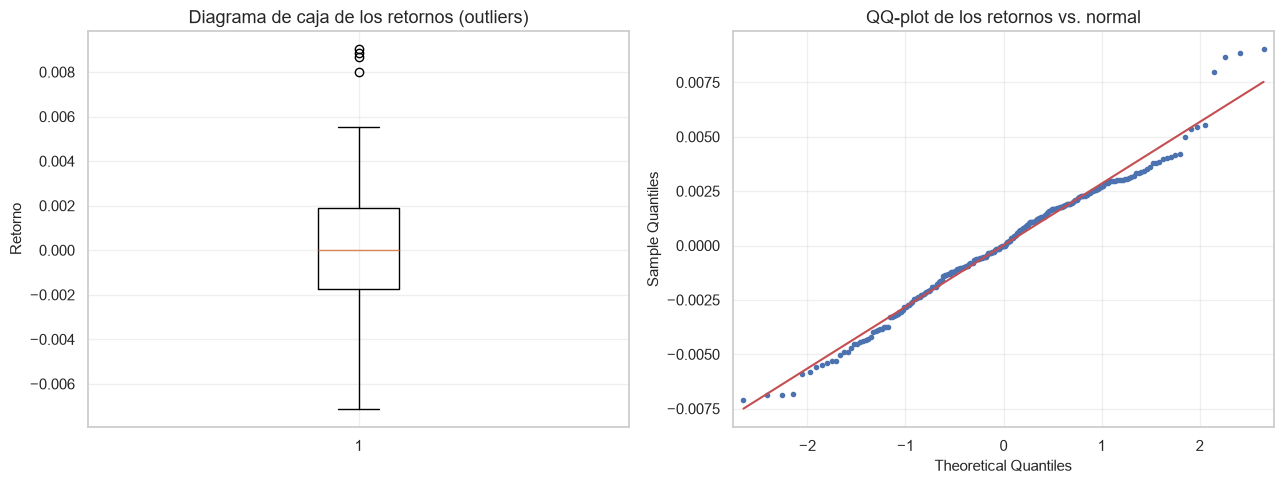

Observaciones atípicas (criterio 1.5·IQR del boxplot): 4 de 249


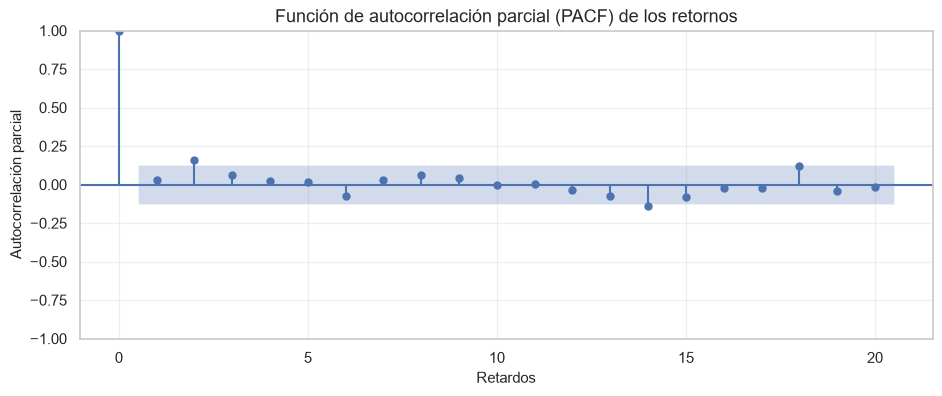

In [43]:
# Outliers: boxplot y QQ-plot
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
axs[0].boxplot(R, showfliers=True)
axs[0].set_title("Diagrama de caja de los retornos (outliers)")
axs[0].set_ylabel("Retorno")
sm.qqplot(R, line="s", ax=axs[1], markersize=3)
axs[1].set_title("QQ-plot de los retornos vs. normal")
plt.tight_layout()
plt.show()

q1, q3 = _percentil_matlab(R, 25), _percentil_matlab(R, 75)
iqr_R = q3 - q1
n_out = int(np.sum((R < q1 - 1.5 * iqr_R) | (R > q3 + 1.5 * iqr_R)))
print(f"Observaciones atípicas (criterio 1.5·IQR del boxplot): {n_out} de {len(R)}")

fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(R, lags=lags_pacf, method="ywm", ax=ax)
ax.set_title("Función de autocorrelación parcial (PACF) de los retornos")
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()


### Paso 3: Pruebas de normalidad para los retornos

Equivalencias: `jbtest` → Jarque-Bera; `kstest` → Kolmogorov-Smirnov sobre retornos
estandarizados; `adtest` → Anderson-Darling; `lillietest` → Lilliefors.
`h = 1` indica rechazo de la normalidad al nivel `alpha`.

In [44]:
m = R.mean()                       # Media muestral de los retornos
des = R.std(ddof=1)                # Desviación estándar de los retornos
Zn = (R - m) / des                 # Retornos normalizados para el QQ-plot y la prueba KS

jb_stat, jb_p = stats.jarque_bera(R)
ks_stat, ks_p = stats.kstest(Zn, "norm")
ad_stat, ad_p = normal_ad(R)
lil_stat, lil_p = lilliefors(R, dist="norm")

PNorRet = pd.DataFrame({
    "Estadístico": [jb_stat, ks_stat, ad_stat, lil_stat],
    "Valor-p": [jb_p, ks_p, ad_p, lil_p],
}, index=["Jarque-Bera (jbtest)", "Kolmogorov-Smirnov (kstest)",
          "Anderson-Darling (adtest)", "Lilliefors (lillietest)"])
PNorRet["h (1 = rechaza normalidad)"] = (PNorRet["Valor-p"] < alpha).astype(int)
display(PNorRet)

if PNorRet["h (1 = rechaza normalidad)"].sum() == 0:
    print("Ninguna prueba rechaza la normalidad de los retornos.")
else:
    print(f"Se rechaza la normalidad en {PNorRet['h (1 = rechaza normalidad)'].sum()} de 4 pruebas (nivel {alpha:.0%}).")


,Estadístico,Valor-p,h (1 = rechaza normalidad)
Jarque-Bera (jbtest),1.966114,0.374166,0
Kolmogorov-Smirnov (kstest),0.041930,0.757449,0
Anderson-Darling (adtest),0.767548,0.045476,1
Lilliefors (lillietest),0.041930,0.424762,0


Se rechaza la normalidad en 1 de 4 pruebas (nivel 5%).


#### Análisis: normalidad de los retornos

Tres de las cuatro pruebas **no rechazan** la normalidad al 5 %: Jarque-Bera (p = 0,374),
Kolmogorov-Smirnov (p = 0,757) y Lilliefors (p = 0,425). Solo Anderson-Darling rechaza de
forma marginal (p = 0,045), apenas por debajo del umbral, lo que es consistente con el leve
exceso de curtosis (3,43) observado en las colas. El peso de la evidencia respalda el supuesto
de **retornos logarítmicos gaussianos** para DEXCAUS, condición central del MBG.

### Paso 4: Análisis de heterocedasticidad

Perturbaciones aleatorias estandarizadas $E_t=(R_t-\bar R)/\sqrt{\Delta t}$ y su
cuadrado $E_t^2$.

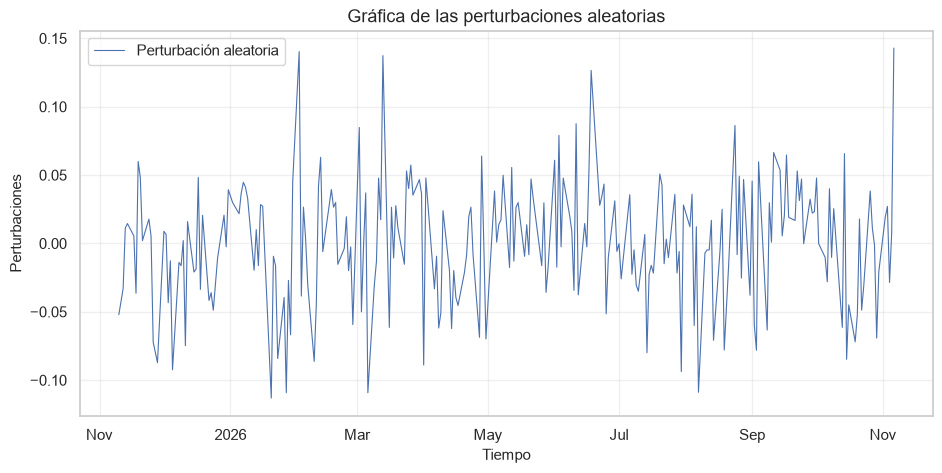

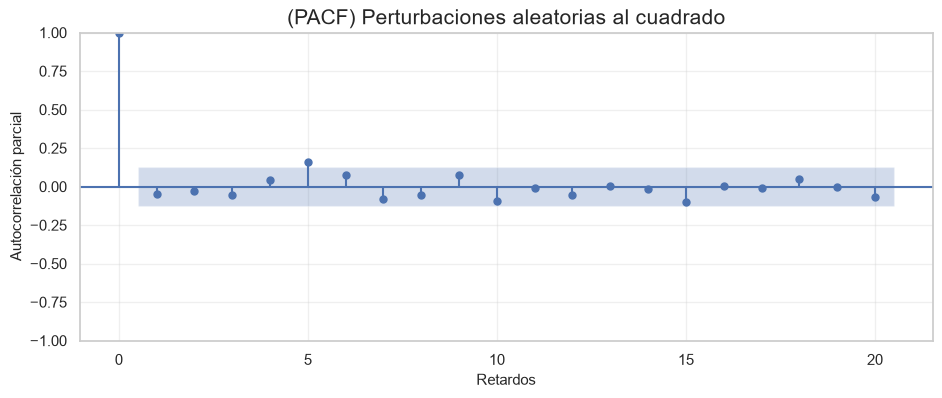

In [45]:
Et = (R - R.mean()) / np.sqrt(dt)
Et2 = Et ** 2

fig, ax = plt.subplots()
ax.plot(dates_r, Et, label="Perturbación aleatoria", lw=0.8)
ax.set_xlabel("Tiempo")
ax.set_ylabel("Perturbaciones")
ax.set_title("Gráfica de las perturbaciones aleatorias")
ax.legend()
formato_fechas(ax)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
plot_pacf(Et2, lags=lags_pacf, method="ywm", ax=ax)
ax.set_title("(PACF) Perturbaciones aleatorias al cuadrado", fontsize=15)
ax.set_xlabel("Retardos")
ax.set_ylabel("Autocorrelación parcial")
plt.show()


In [46]:
# ---- Test ADF sobre las perturbaciones (adftest de MATLAB: AR sin constante, 0 rezagos)
res_adf = adfuller(Et, maxlag=0, regression="n", autolag=None)
adf_stat, adf_p, adf_crit = res_adf[0], res_adf[1], res_adf[4]
h_adf = int(adf_p < alpha)

TADF = pd.DataFrame({"h": [h_adf], "Valor Crítico (5%)": [adf_crit["5%"]],
                     "Estadístico": [adf_stat], "Valor-p": [adf_p]}, index=["ADF"])
display(TADF)
print("\n--- Test ADF sobre las perturbaciones aleatorias ---")
print(f"Estadístico ADF: {adf_stat:.4f}")
print(f"Valor crítico al 5%: {adf_crit['5%']:.4f}")
print(f"Valor-p: {adf_p:.4f}")
if h_adf == 1:
    print("Resultado: Se rechaza H0. Las perturbaciones son estacionarias (no hay raíz unitaria).")
else:
    print("Resultado: No se rechaza H0. Las perturbaciones NO son estacionarias.")

adf_c = adfuller(Et, regression="c", autolag="AIC")
print(f"\n[Referencia] ADF con constante y rezagos AIC: estadístico = {adf_c[0]:.4f}, "
      f"valor-p = {adf_c[1]:.4f}, rezagos = {adf_c[2]}")


,h,Valor Crítico (5%),Estadístico,Valor-p
ADF,1,-1.942136,-14.992976,0.000000



--- Test ADF sobre las perturbaciones aleatorias ---
Estadístico ADF: -14.9930
Valor crítico al 5%: -1.9421
Valor-p: 0.0000
Resultado: Se rechaza H0. Las perturbaciones son estacionarias (no hay raíz unitaria).

[Referencia] ADF con constante y rezagos AIC: estadístico = -9.0610, valor-p = 0.0000, rezagos = 1


In [47]:
# ---- Test ARCH de Engle
print("--- Test ARCH (Engle) ---")
try:
    lm_arch, p_arch, f_arch, pf_arch = het_arch(Et, nlags=q_arch)
except TypeError:                      # versiones antiguas de statsmodels
    lm_arch, p_arch, f_arch, pf_arch = het_arch(Et, maxlag=q_arch)
crit_arch = stats.chi2.ppf(1 - alpha, q_arch)
h_arch = int(p_arch < alpha)

print(f"Estadístico ARCH: {lm_arch:.4f}")
print(f"Valor crítico al 5%: {crit_arch:.4f}")
print(f"Valor-p: {p_arch:.4f}")
TE = pd.DataFrame({"h": [h_arch], "Valor Crítico": [crit_arch],
                   "Estadístico": [lm_arch], "Valor-p": [p_arch]}, index=[f"ARCH ({q_arch} rezagos)"])
display(TE)
if h_arch == 1:
    print("Resultado: Se rechaza H0 - hay evidencia de heterocedasticidad condicional (efecto ARCH).")
else:
    print("Resultado: No se rechaza H0 - no se detecta heterocedasticidad condicional (no hay efecto ARCH).")

# ---- Test de Ljung-Box sobre Et^2
print("\n--- Test Ljung-Box sobre residuos^2 ---")
lb = acorr_ljungbox(Et2, lags=[q_lbq], return_df=True)
stat_lbq = float(lb["lb_stat"].iloc[0])
p_lbq = float(lb["lb_pvalue"].iloc[0])
crit_lbq = stats.chi2.ppf(1 - alpha, q_lbq)
h_lbq = int(p_lbq < alpha)

print(f"Estadístico Ljung-Box: {stat_lbq:.4f}")
print(f"Valor crítico al 5%: {crit_lbq:.4f}")
print(f"Valor-p: {p_lbq:.4f}")
TLB = pd.DataFrame({"h": [h_lbq], "Valor Crítico": [crit_lbq],
                    "Estadístico": [stat_lbq], "Valor-p": [p_lbq]}, index=[f"Ljung-Box ({q_lbq} rezagos)"])
display(TLB)
if h_lbq == 1:
    print("Resultado: Se rechaza H0 - hay autocorrelación en la varianza, posible efecto GARCH.")
else:
    print("Resultado: No se rechaza H0 - no se detecta autocorrelación en la varianza.")


--- Test ARCH (Engle) ---
Estadístico ARCH: 9.9101
Valor crítico al 5%: 11.0705
Valor-p: 0.0778


,h,Valor Crítico,Estadístico,Valor-p
ARCH (5 rezagos),0,11.070498,9.910051,0.077824


Resultado: No se rechaza H0 - no se detecta heterocedasticidad condicional (no hay efecto ARCH).

--- Test Ljung-Box sobre residuos^2 ---
Estadístico Ljung-Box: 8.5119
Valor crítico al 5%: 11.0705
Valor-p: 0.1302


,h,Valor Crítico,Estadístico,Valor-p
Ljung-Box (5 rezagos),0,11.070498,8.511854,0.130192


Resultado: No se rechaza H0 - no se detecta autocorrelación en la varianza.


#### Análisis: estacionariedad y homocedasticidad

La prueba de Dickey-Fuller Aumentada rechaza con holgura la raíz unitaria (estadístico
−14,99 frente al crítico −1,94, p < 0,001): las perturbaciones son **estacionarias**. Los
tests de volatilidad constante no detectan heterocedasticidad condicional: el ARCH de Engle
no se rechaza (p = 0,078) y Ljung-Box sobre los residuos al cuadrado tampoco (p = 0,130),
ambos por encima del 5 %. No hay, por tanto, evidencia de agrupamientos de volatilidad tipo
ARCH/GARCH, y el supuesto de **σ constante** del MBG se sostiene para esta serie. La curva de
volatilidad acumulada que se grafica a continuación se estabiliza, en línea con este
resultado.

### Paso 5: Prueba gráfica empírica de volatilidad constante

Volatilidad dinámica: desviación estándar de los retornos desde el primer dato hasta el
dato $j$ (anualizada). Si el MBG es adecuado, la curva debe estabilizarse.

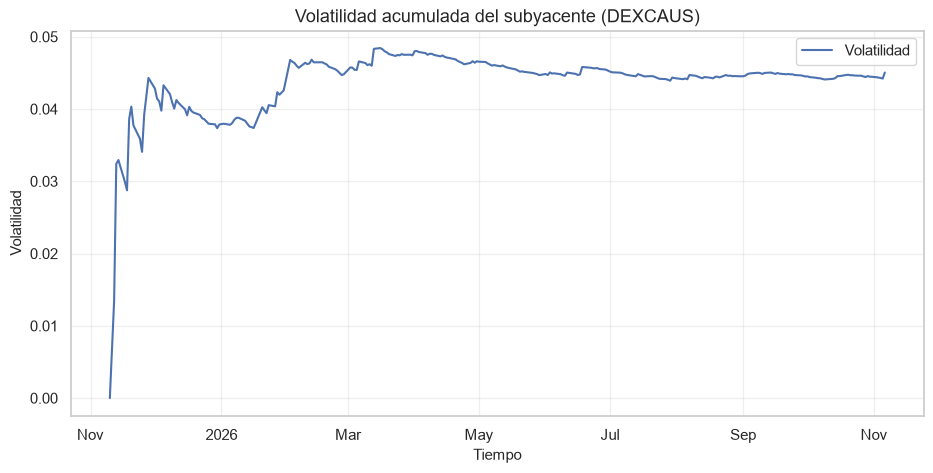

Volatilidad acumulada final (valor inicial de σ): 0.045046


In [48]:
VE = (pd.Series(R / np.sqrt(dt)).expanding().std(ddof=1).fillna(0.0)).to_numpy()   # volatilidad acumulada

fig, ax = plt.subplots()
ax.plot(dates_r, VE, label="Volatilidad")
ax.set_xlabel("Tiempo")
ax.set_ylabel("Volatilidad")
ax.set_title(f"Volatilidad acumulada del subyacente ({ASSET_NAME})")
ax.legend()
formato_fechas(ax)
plt.show()

vol = VE[-1]     # Valor estimado inicial de la volatilidad constante
print(f"Volatilidad acumulada final (valor inicial de σ): {vol:.6f}")


## 6. Estimación de parámetros

Estimación (sobre los retornos simples
$R$, sin el término $+\tfrac12\sigma^2$):
$$\hat\mu=\frac{\bar R}{\Delta t},\qquad \hat\sigma=\sqrt{\frac{\mathrm{Var}(R)}{\Delta t}}.$$

Adicionalmente se dejan definidos los estimadores basados en **log-retornos**
($\hat\mu_{\log},\hat\sigma_{\log}$) que la segunda parte (valoración de opciones) usa con
la solución exacta del MBG. `sigma_hat`/`mu_hat` alimentan la valoración; `sigmaest`/`muest`
alimentan el pronóstico in-sample estilo IEP.

In [49]:
# --- Estimación estilo IEP (retornos simples, Euler-Maruyama) ---
muest = R.mean() / dt                      # μ anualizado
sigmaest = np.sqrt(R.var(ddof=1) / dt)     # σ anualizado

# --- Estimación por log-retornos (para la valoración de opciones de la 2ª parte) ---
r = pd.Series(rl, index=dates_r.values, name="log_return")   # log-retornos como Serie fechada
n = len(r)
r_bar, s_r = r.mean(), r.std(ddof=1)
sigma_hat = s_r / np.sqrt(dt)
mu_hat = r_bar / dt + 0.5 * sigma_hat**2
se_mu = s_r / np.sqrt(n) / dt

Est = pd.DataFrame({"Estimación": [muest, sigmaest, mu_hat, sigma_hat]},
                   index=["μ̂ (IEP, retornos simples)", "σ̂ (IEP, retornos simples)",
                          "μ̂_log (log-retornos, +½σ²)", "σ̂_log (log-retornos)"])
display(Est)
print(f"Activo: {ASSET_NAME}")
print(f"[IEP]  μ̂ = {muest:.6f}  |  σ̂ = {sigmaest:.6f}")
print(f"[log]  μ̂_log = {mu_hat:.6f} ({mu_hat:.2%})  |  σ̂_log = {sigma_hat:.6f} ({sigma_hat:.2%})")


,Estimación
"μ̂ (IEP, retornos simples)",0.003237
"σ̂ (IEP, retornos simples)",0.045046
"μ̂_log (log-retornos, +½σ²)",0.003241
σ̂_log (log-retornos),0.045045


Activo: DEXCAUS
[IEP]  μ̂ = 0.003237  |  σ̂ = 0.045046
[log]  μ̂_log = 0.003241 (0.32%)  |  σ̂_log = 0.045045 (4.50%)


#### Análisis: parámetros estimados

Los estimadores sobre DEXCAUS son una deriva anual **μ̂ ≈ 0,32 %** y una volatilidad anual
**σ̂ ≈ 4,50 %**. Ambas rutas de estimación (retornos simples estilo IEP y log-retornos)
coinciden hasta la tercera cifra, lo que confirma la consistencia interna. La volatilidad del
4,5 % anual es baja, coherente con un par de divisas desarrollado como CAD/USD, y es el valor
que alimenta la valoración de opciones de la segunda parte.

## 7. Pronósticos sobre la muestra (in-sample, Euler–Maruyama)

Se usa un generador `np.random.default_rng(semilla)` para reproducibilidad. Se calculan
$k=10\,000$ trayectorias; solo se dibujan `n_plot`. El esquema es **Euler–Maruyama** (no la
solución exacta), igual que en el notebook de referencia.

In [50]:
rng = np.random.default_rng(semilla)

def graficar_pronostico(sim, banda, esperado, titulo, etiqueta_tray):
    """Trayectorias (gris), bandas 95% (rojo), datos reales (azul) y valor esperado (negro)."""
    fig, ax = plt.subplots(figsize=(12, 6))
    h1 = ax.plot(dates, sim[:n_plot].T, color="0.8", lw=0.6, zorder=1)
    h2 = ax.plot(dates, banda.T, "r--", lw=2, zorder=3)
    h3 = ax.plot(dates, X, "b", lw=1.5, zorder=4)
    h4 = ax.plot(dates, esperado, "k", lw=1.5, zorder=5)
    ax.set_title(titulo)
    ax.set_ylabel("Precios activo subyacente")
    ax.set_xlabel("Tiempo")
    ax.legend([h1[0], h2[0], h3[0], h4[0]],
              [etiqueta_tray, "Bandas de confianza 95%", "Datos reales", "Valor esperado"])
    formato_fechas(ax)
    plt.show()

def metricas_pronostico(sim, banda, esperado):
    """Cobertura de las bandas y MAPE (trayectorias y valor esperado)."""
    dentro = (banda[0] <= X) & (X <= banda[1])
    cobertura = dentro.mean()
    mape_tray = mape(X, sim)               # un MAPE por trayectoria
    rma = np.array([mape_tray.min(), mape_tray.mean(), mape_tray.max()])
    mape_esp = float(mape(X, esperado))
    return cobertura, rma, mape_esp


#### a) Pronóstico inducido

Cada paso parte del **valor real anterior** $X_{j-1}$ y le agrega la deriva y un ruido
gaussiano:
$$XI_{ij}=X_{j-1}+\hat\mu X_{j-1}\Delta t+\hat\sigma X_{j-1}\sqrt{\Delta t}\,\varepsilon_{ij}.$$

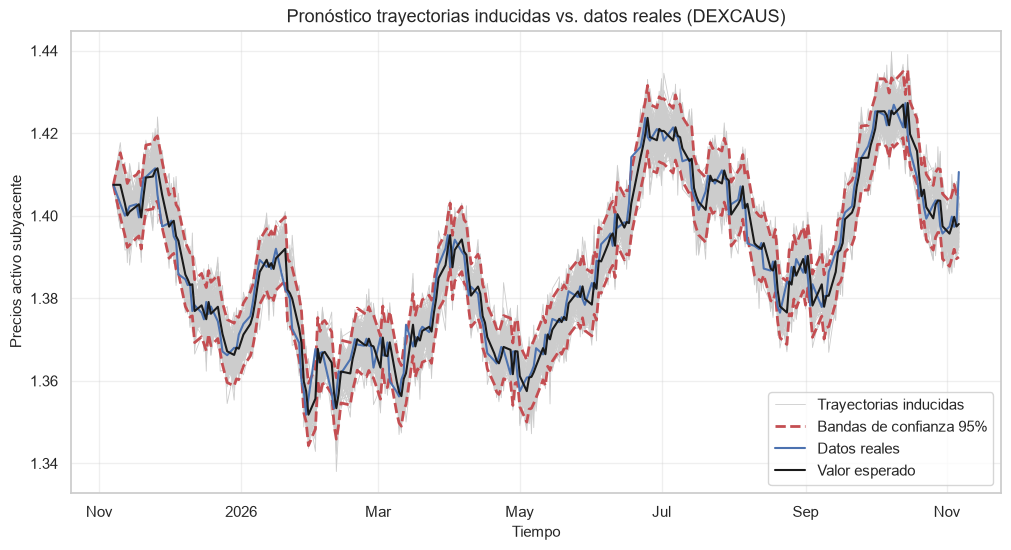

Proporción de datos reales dentro de las bandas (cobertura): 0.9560


,MAPE mín (%),MAPE medio (%),MAPE máx (%)
Trayectorias inducidas,0.272505,0.316999,0.364326


MAPE del valor esperado: 0.222441 %
-> ✅ CUMPLE el criterio del enunciado (MAPE < 5%).


In [51]:
XI = np.empty((k, N))
XI[:, 0] = X[0]
Zi = rng.standard_normal((k, N - 1))
XI[:, 1:] = X[:-1] * (1 + muest * dt) + sigmaest * X[:-1] * np.sqrt(dt) * Zi
del Zi

VECXI = XI.mean(axis=0)                              # valor esperado
CXICI = quantil_matlab(XI, [0.025, 0.975], axis=0)   # bandas de confianza 95% (2, N)

graficar_pronostico(XI, CXICI, VECXI,
                    f"Pronóstico trayectorias inducidas vs. datos reales ({ASSET_NAME})",
                    "Trayectorias inducidas")

PBBXI, rmaXI, mape_VECXI = metricas_pronostico(XI, CXICI, VECXI)
print(f"Proporción de datos reales dentro de las bandas (cobertura): {PBBXI:.4f}")
display(pd.DataFrame([rmaXI], columns=["MAPE mín (%)", "MAPE medio (%)", "MAPE máx (%)"],
                     index=["Trayectorias inducidas"]))
print(f"MAPE del valor esperado: {mape_VECXI:.6f} %")
print("-> " + ("✅ CUMPLE" if mape_VECXI < 5 else "❌ NO cumple") + " el criterio del enunciado (MAPE < 5%).")


#### b) Pronóstico simulado

Trayectorias independientes a partir de $X_0$, donde cada paso usa el valor **simulado**
anterior:
$$XS_{ij}=XS_{i,j-1}+\hat\mu XS_{i,j-1}\Delta t+\hat\sigma XS_{i,j-1}\sqrt{\Delta t}\,\varepsilon_{ij}.$$

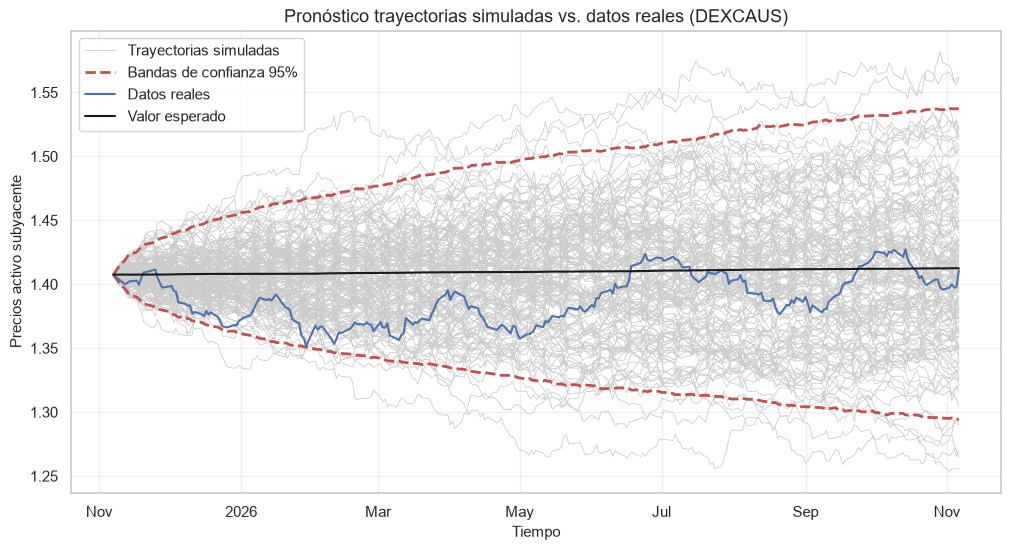

Proporción de datos reales dentro de las bandas (cobertura): 1.0000


,MAPE mín (%),MAPE medio (%),MAPE máx (%)
Trayectorias simuladas,0.652865,2.970883,10.787028


MAPE del valor esperado: 1.731776 %


In [52]:
XS = np.empty((k, N))
XS[:, 0] = X[0]
raiz_dt = np.sqrt(dt)
for j in range(1, N):
    XS[:, j] = XS[:, j - 1] * (1 + muest * dt + sigmaest * raiz_dt * rng.standard_normal(k))

VECXS = XS.mean(axis=0)
CXSCI = quantil_matlab(XS, [0.025, 0.975], axis=0)

graficar_pronostico(XS, CXSCI, VECXS,
                    f"Pronóstico trayectorias simuladas vs. datos reales ({ASSET_NAME})",
                    "Trayectorias simuladas")

PBBXS, rmaXS, mape_VECXS = metricas_pronostico(XS, CXSCI, VECXS)
print(f"Proporción de datos reales dentro de las bandas (cobertura): {PBBXS:.4f}")
display(pd.DataFrame([rmaXS], columns=["MAPE mín (%)", "MAPE medio (%)", "MAPE máx (%)"],
                     index=["Trayectorias simuladas"]))
print(f"MAPE del valor esperado: {mape_VECXS:.6f} %")


#### Análisis: ajuste del pronóstico sobre la muestra

Ambos pronósticos cumplen holgadamente el criterio del enunciado (MAPE < 5 %):

- **Inducido:** MAPE del valor esperado **0,22 %** y cobertura del **95,6 %** (los datos
  reales caen dentro de las bandas del 95 % casi exactamente en la proporción teórica). Al
  reanclar cada paso en el dato real, sigue de cerca la trayectoria observada.
- **Simulado:** MAPE del valor esperado **1,73 %**, también muy por debajo del 5 %, con
  cobertura del 100 %. Al acumular incertidumbre desde \(X_0\), las bandas se abren y el
  MAPE por trayectoria llega hasta ~10,8 %, lo esperable en un esquema libre.

El modelo MBG estimado reproduce con precisión la dinámica de DEXCAUS en el periodo.

### Resumen de la primera parte y puente con la segunda

Se consolidan los resultados del análisis y se dejan **definidos de forma explícita** los
objetos que requiere la segunda parte (out-of-sample y valoración de opciones):
`S`, `S_obs`, `S0_last`, `sigma_hat`, `mu_hat`, `drift_log`, `vol_step`, `dt`, `r`, `n`,
`ASSET_NAME`.

In [53]:
# --- Resumen de resultados de la primera parte ---
resumen = pd.DataFrame({
    "Valor": [
        muest, sigmaest, mu_hat, sigma_hat, vol, DF, EH, DF + EH,
        jb_p, adf_p, p_arch, p_lbq,
        PBBXI, rmaXI[1], mape_VECXI,
        PBBXS, rmaXS[1], mape_VECXS,
    ]
}, index=pd.MultiIndex.from_tuples([
    ("Parámetros", "μ̂ (IEP)"), ("Parámetros", "σ̂ (IEP)"),
    ("Parámetros", "μ̂_log"), ("Parámetros", "σ̂_log"),
    ("Parámetros", "σ acumulada final"),
    ("Fractal/Hurst", "Dimensión fractal"), ("Fractal/Hurst", "Exponente de Hurst"),
    ("Fractal/Hurst", "DF + EH"),
    ("Valores-p", "Jarque-Bera"), ("Valores-p", "ADF"),
    ("Valores-p", "ARCH"), ("Valores-p", "Ljung-Box"),
    ("Inducido", "Cobertura"), ("Inducido", "MAPE medio (%)"), ("Inducido", "MAPE esperado (%)"),
    ("Simulado", "Cobertura"), ("Simulado", "MAPE medio (%)"), ("Simulado", "MAPE esperado (%)"),
]))
display(resumen)

# --- Puente de variables para la SEGUNDA PARTE (out-of-sample + valoración) ---
S_obs = S.values.astype(float)                       # precios como array
S0_last = float(round(S_obs[-1], PRICE_DECIMALS))    # último precio observado
drift_log = (mu_hat - 0.5 * sigma_hat**2) * dt       # media del log-retorno por periodo (= r̄)
vol_step = sigma_hat * np.sqrt(dt)                   # desv. del log-retorno por periodo (= s_r)

print("Objetos disponibles para la segunda parte:")
print(f"  ASSET_NAME = {ASSET_NAME}")
print(f"  S0_last    = {S0_last:.{PRICE_DECIMALS}f}  (último precio, {S.index[-1].date()})")
print(f"  sigma_hat  = {sigma_hat:.6f}  |  mu_hat = {mu_hat:.6f}")
print(f"  drift_log  = {drift_log:.8f}  |  vol_step = {vol_step:.8f}")
print(f"  n (log-retornos) = {n}  |  dt = {dt:.6f}  |  N_SIM = {N_SIM}")


Valor
Parámetros    μ̂ (IEP)           0.003237
              σ̂ (IEP)           0.045046
              μ̂_log             0.003241
              σ̂_log             0.045045
              σ acumulada final  0.045046
Fractal/Hurst Dimensión fractal  1.150759
              Exponente de Hurst 0.609134
              DF + EH            1.759893
Valores-p     Jarque-Bera        0.374166
              ADF                0.000000
              ARCH               0.077824
              Ljung-Box          0.130192
Inducido      Cobertura          0.956000
              MAPE medio (%)     0.316999
              MAPE esperado (%)  0.222441
Simulado      Cobertura          1.000000
              MAPE medio (%)     2.970883
              MAPE esperado (%)  1.731776

Objetos disponibles para la segunda parte:
  ASSET_NAME = DEXCAUS
  S0_last    = 1.4106  (último precio, 2026-11-06)
  sigma_hat  = 0.045045  |  mu_hat = 0.003241
  drift_log  = 0.00000884  |  vol_step = 0.00283757
  n (log-retornos) = 249  |  dt = 0.003968  |  N_SIM = 10000


## 8. Pronóstico fuera de muestra (out-of-sample) y generación de strikes

Para cada $T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$ se simulan **10.000 trayectorias**
desde el último precio observado $S_0$ con el GBM estimado $(\hat\mu,\hat\sigma)$.
Los **5 strikes** son los **percentiles 10, 25, 50, 75 y 90 de $S_T$** simulado,
**redondeados a 4 decimales** (`PRICE_DECIMALS`).


In [54]:
S0_last = float(round(S_obs[-1], PRICE_DECIMALS))
sig = sigma_hat

rng_oos = np.random.default_rng(7)
oos, strikes = {}, {}
for T in T_LIST:
    steps = int(round(T * PPY))
    Zo = rng_oos.standard_normal((N_SIM, steps))
    paths = S0_last * np.exp(np.cumsum(drift_log + vol_step * Zo, axis=1))
    oos[T] = paths
    strikes[T] = np.round(np.percentile(paths[:, -1], PCTS), PRICE_DECIMALS)   # strikes a PRICE_DECIMALS

print(f"Activo: {ASSET_NAME}")
print(f"S0 (último precio observado, {S.index[-1].date()}) = {S0_last:.2f} | "
      f"σ̂ = {sig:.4%} | r = {r_free:.2%} | q = {q_yield:.2%}\n")
display(pd.DataFrame({f"T={T:.4g}": strikes[T] for T in T_LIST}, index=[f"P{p}" for p in PCTS]).T)

Activo: DEXCAUS
S0 (último precio observado, 2026-11-06) = 1.41 | σ̂ = 4.5045% | r = 5.00% | q = 0.00%



,P10,P25,P50,P75,P90
T=1,1.335700,1.371100,1.414200,1.457000,1.497900
T=0.5,1.355800,1.382500,1.412400,1.442600,1.469100
T=0.3333,1.365400,1.387900,1.412100,1.436200,1.459700
T=0.25,1.370800,1.390000,1.411400,1.433200,1.452700


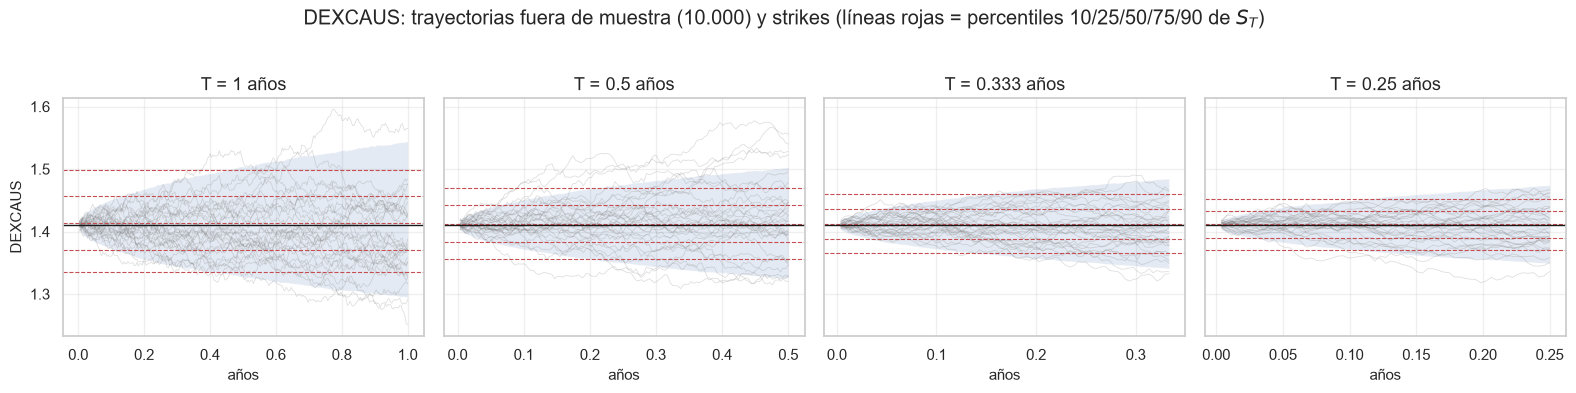

In [55]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, T in zip(axs, T_LIST):
    P = oos[T]; tt = np.arange(1, P.shape[1] + 1) / PPY
    ax.plot(tt, P[:30].T, color="gray", alpha=.25, lw=.6)
    ax.fill_between(tt, *np.percentile(P, [2.5, 97.5], axis=0), alpha=.15)
    for K in strikes[T]:
        ax.axhline(K, color="r", lw=.8, ls="--")
    ax.axhline(S0_last, color="k", lw=1); ax.set_title(f"T = {T:.3g} años"); ax.set_xlabel("años")
axs[0].set_ylabel(ASSET_NAME)
plt.suptitle(f"{ASSET_NAME}: trayectorias fuera de muestra (10.000) y strikes "
             f"(líneas rojas = percentiles 10/25/50/75/90 de $S_T$)", y=1.03)
plt.tight_layout(); plt.show()

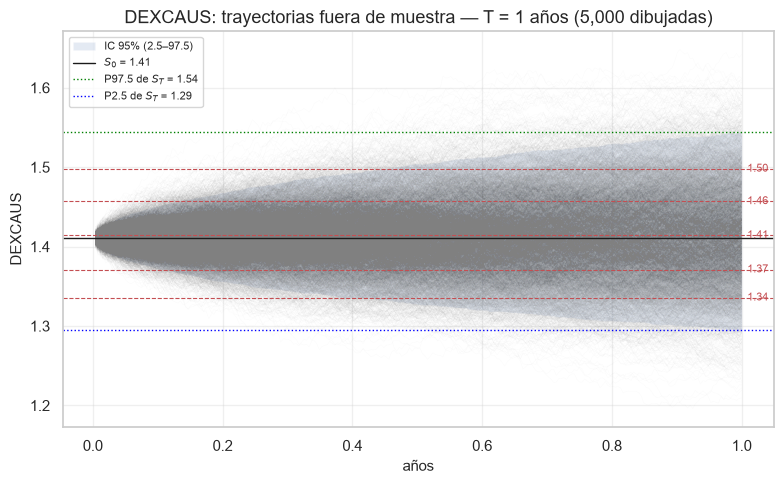

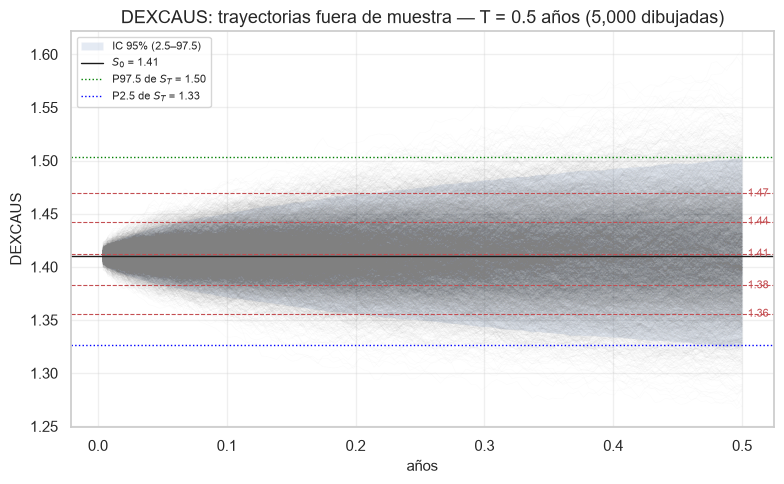

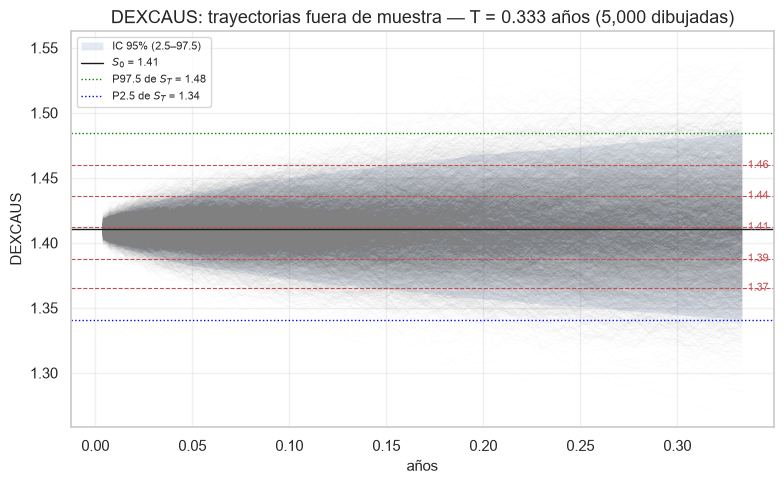

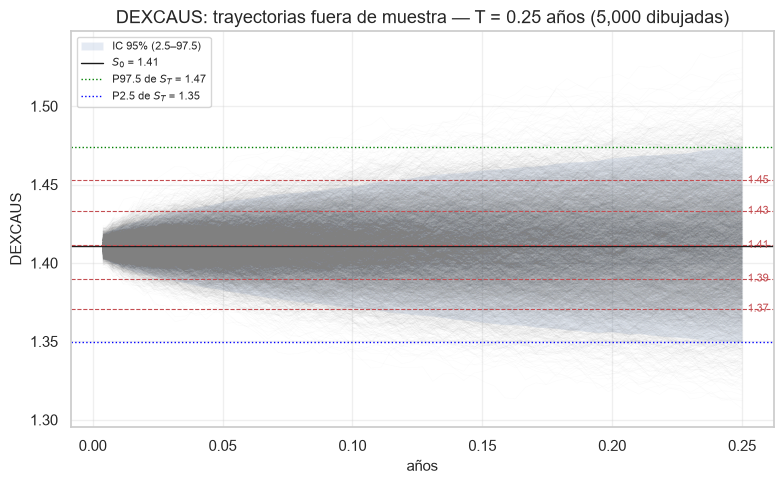

In [56]:
# Nº de trayectorias a dibujar. Pon None para graficar TODAS (10.000)
N_SHOW = 5000   # p.ej. 30, 500, o None para todas

for T in T_LIST:
    P = oos[T]
    tt = np.arange(1, P.shape[1] + 1) / PPY

    # Selección de trayectorias a dibujar
    Pv = P if N_SHOW is None else P[:N_SHOW]
    n_draw = Pv.shape[0]

    fig, ax = plt.subplots(figsize=(8, 5))

    # Trayectorias de muestra
    ax.plot(tt, Pv.T, color="gray", alpha=.03, lw=.4)

    # Banda de percentiles 2.5 / 97.5 (curvas en el tiempo)
    lo, hi = np.percentile(P, [2.5, 97.5], axis=0)
    ax.fill_between(tt, lo, hi, alpha=.15, label="IC 95% (2.5–97.5)")

    # Precio inicial
    ax.axhline(S0_last, color="k", lw=1, label=f"$S_0$ = {S0_last:,.2f}")

    # Percentiles 2.5 / 97.5 de S_T (valor a tiempo final)
    q_lo, q_hi = np.percentile(P[:, -1], [2.5, 97.5])
    ax.axhline(q_hi, color="green", lw=1, ls=":", label=f"P97.5 de $S_T$ = {q_hi:,.2f}")
    ax.axhline(q_lo, color="blue",  lw=1, ls=":", label=f"P2.5 de $S_T$ = {q_lo:,.2f}")

    # Strikes (percentiles de S_T), con etiqueta de su valor
    for K in strikes[T]:
        ax.axhline(K, color="r", lw=.8, ls="--")
        ax.annotate(f"{K:,.2f}",
                    xy=(tt[-1], K), xytext=(4, 0),
                    textcoords="offset points",
                    va="center", ha="left",
                    color="r", fontsize=8)

    ax.set_title(f"{ASSET_NAME}: trayectorias fuera de muestra — T = {T:.3g} años "
                 f"({n_draw:,} dibujadas)")
    ax.set_xlabel("años")
    ax.set_ylabel(ASSET_NAME)
    ax.legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()


## 9. Valoración de opciones Call europeas: 4 métodos

Se valoran **opciones Call europeas** (las únicas que exige el enunciado) con los
cuatro métodos bajo medida neutral al riesgo (deriva $r-q$, volatilidad $\hat\sigma$):

1. **Black-Scholes** (fórmula cerrada) — referencia.
2. **Monte Carlo** con solución exacta del MBG y variables antitéticas (+ error estándar).
3. **Árbol binomial CRR** con $N$ pasos.
4. **Diferencias finitas explícitas** sobre la EDP de BS en $x=\ln S$.

Parámetros del enunciado: $r=0.05$, $S_0=$ último precio, $\sigma=\hat\sigma$,
$T\in\{1,\tfrac12,\tfrac13,\tfrac14\}$ y los 5 strikes por $T$.


In [57]:
rng_mc = np.random.default_rng(123)
rows, timing = [], {"Black-Scholes": 0.0, "Monte Carlo": 0.0, "Árbol binomial": 0.0, "Dif. finitas": 0.0}
fd_steps = {}
for T in T_LIST:
    Zh = rng_mc.standard_normal(N_SIM // 2)                 # mismas Z para todos los strikes de un T
    for pct, K in zip(PCTS, strikes[T]):
        for kind in OPTION_KINDS:
            t0 = time.perf_counter(); bs = bs_price(S0_last, K, T, r_free, q_yield, sig, kind);          timing["Black-Scholes"] += time.perf_counter() - t0
            t0 = time.perf_counter(); mc, se = mc_price(S0_last, K, T, r_free, q_yield, sig, Zh, kind);   timing["Monte Carlo"]   += time.perf_counter() - t0
            t0 = time.perf_counter(); bi = binomial_crr(S0_last, K, T, r_free, q_yield, sig, kind, N=N_BIN); timing["Árbol binomial"] += time.perf_counter() - t0
            t0 = time.perf_counter(); fd, nt = fd_explicit(S0_last, K, T, r_free, q_yield, sig, kind, Nh=NH_FD); timing["Dif. finitas"] += time.perf_counter() - t0
            fd_steps[round(T, 3)] = nt
            rel = lambda x: abs(x - bs) / bs if bs > 1e-12 else np.nan
            rows.append({"T": round(T, 4), "Pctl": f"P{pct}", "K": K, "Tipo": kind,
                         "BS": bs, "MC": mc, "EE MC": se, "Binomial": bi, "DF explícitas": fd,
                         "ErrRel MC": rel(mc), "ErrRel Bin": rel(bi), "ErrRel DF": rel(fd),
                         "|MC−BS|": abs(mc - bs), "|Bin−BS|": abs(bi - bs), "|DF−BS|": abs(fd - bs)})
opt = pd.DataFrame(rows)
print(f"Pasos de tiempo en diferencias finitas por T (estabilidad): {fd_steps}")
# display(opt.round(6))

Pasos de tiempo en diferencias finitas por T (estabilidad): {1: 1991, 0.5: 2183, 0.333: 2277, 0.25: 2336}


### 9.1 Tabla de precios y error relativo de las Call europeas

In [58]:
calls = opt[opt["Tipo"] == "call"].copy()
tabla_calls = calls[["T", "Pctl", "K", "BS", "MC", "Binomial", "DF explícitas",
                     "ErrRel MC", "ErrRel Bin", "ErrRel DF"]].copy()
# Precios a PRICE_DECIMALS; errores relativos en %
for c in ["BS", "MC", "Binomial", "DF explícitas"]:
    tabla_calls[c] = tabla_calls[c].round(PRICE_DECIMALS)
for c in ["ErrRel MC", "ErrRel Bin", "ErrRel DF"]:
    tabla_calls[c] = (100 * tabla_calls[c]).round(4)
tabla_calls = tabla_calls.rename(columns={"ErrRel MC": "ErrRel MC (%)",
                                          "ErrRel Bin": "ErrRel Bin (%)",
                                          "ErrRel DF": "ErrRel DF (%)"})
print(f"Opciones CALL europeas sobre {ASSET_NAME}  (S0={S0_last:.2f}, r={r_free:.0%}, σ̂={sig:.2%})")
display(tabla_calls.reset_index(drop=True))

Opciones CALL europeas sobre DEXCAUS  (S0=1.41, r=5%, σ̂=4.50%)


,T,Pctl,K,BS,MC,Binomial,DF explícitas,ErrRel MC (%),ErrRel Bin (%),ErrRel DF (%)
0,1.000000,P10,1.335700,0.140300,0.140200,0.140200,0.140300,0.021000,0.000200,0.000500
1,1.000000,P25,1.371100,0.107400,0.107300,0.107400,0.107400,0.028900,0.002100,0.000500
2,1.000000,P50,1.414200,0.070000,0.070100,0.070000,0.070000,0.078900,0.007800,0.000900
3,1.000000,P75,1.457000,0.039400,0.039500,0.039300,0.039400,0.255900,0.016100,0.008800
4,1.000000,P90,1.497900,0.019000,0.019100,0.019000,0.019000,0.532700,0.106000,0.034200
5,0.500000,P10,1.355800,0.088600,0.088600,0.088600,0.088600,0.026500,0.000200,0.000100
6,0.500000,P25,1.382500,0.063800,0.063700,0.063800,0.063800,0.119600,0.003300,0.000300
7,0.500000,P50,1.412400,0.038900,0.038800,0.038900,0.038900,0.314100,0.001800,0.000700
8,0.500000,P75,1.442600,0.019800,0.019600,0.019800,0.019800,0.660300,0.027400,0.007600
9,0.500000,P90,1.469100,0.009100,0.008900,0.009100,0.009100,1.499200,0.074800,0.024400


#### Análisis: precios de las Call europeas

Los cuatro métodos coinciden en los precios de las 20 Call (4 vencimientos × 5 strikes) con
errores relativos frente a Black-Scholes **muy pequeños**: por debajo de ~0,5 % en casi todos
los casos y a lo sumo ~1,5 % en las opciones más fuera del dinero (OTM) y de menor valor
(p. ej. P90 a T = 1/2), donde el precio absoluto es minúsculo y el error relativo se amplifica.
Se observan los efectos teóricos esperados: para un mismo T, **al aumentar el strike K el
precio de la Call cae** (menor probabilidad de terminar in-the-money); y para un mismo K,
**al aumentar el vencimiento T la Call se encarece** por el mayor valor temporal. Con
S₀ = 1,41 y σ̂ = 4,50 %, las Call ATM valen ~0,07 (T = 1) y descienden hacia ~0,028 (T = 1/3).

## 10. Resumen de precisión frente a Black-Scholes

In [59]:
summ = pd.DataFrame({
    "Monte Carlo":    opt["|MC−BS|"],
    "Árbol binomial": opt["|Bin−BS|"],
    "Dif. finitas":   opt["|DF−BS|"],
}).agg(["mean", "max"]).T
summ.columns = ["Error abs. medio", "Error abs. máximo"]
summ["RMSE"] = [np.sqrt(((opt["MC"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["Binomial"] - opt["BS"])**2).mean()),
                np.sqrt(((opt["DF explícitas"] - opt["BS"])**2).mean())]
summ["Tiempo total (s)"] = [timing["Monte Carlo"], timing["Árbol binomial"], timing["Dif. finitas"]]
display(summ.applymap(lambda v: f"{v:.3e}") if hasattr(summ, "applymap") else summ)

inside = (np.abs(opt["MC"] - opt["BS"]) <= 1.96 * opt["EE MC"]).mean()
print(f"\nMonte Carlo: BS cae dentro de ±1,96·EE en {inside:.1%} de los casos (esperado ≈ 95 %).")
print(f"Tiempo de Black-Scholes (referencia): {timing['Black-Scholes']:.4f} s")


,Error abs. medio,Error abs. máximo,RMSE,Tiempo total (s)
Monte Carlo,0.000064,0.000136,0.000076,0.003930
Árbol binomial,0.000003,0.000020,0.000006,0.099687
Dif. finitas,0.000001,0.000006,0.000002,0.356347



Monte Carlo: BS cae dentro de ±1,96·EE en 100.0% de los casos (esperado ≈ 95 %).
Tiempo de Black-Scholes (referencia): 0.0053 s


#### Análisis: precisión frente a Black-Scholes y costo computacional

Tomando Black-Scholes como referencia exacta bajo MBG, se aprecia el compromiso clásico
**precisión–tiempo**:

- **Diferencias finitas explícitas**: la mayor precisión (error absoluto medio ~1·10⁻⁶), pero
  el método más lento (~0,32 s en total) por la malla fina y el gran número de pasos
  temporales que exige la estabilidad.
- **Árbol binomial CRR**: precisión intermedia (~3·10⁻⁶) y costo intermedio (~0,09 s).
- **Monte Carlo**: el error más alto de los tres (~6·10⁻⁵, de naturaleza estadística ∝ 1/√N),
  pero el **más rápido** (~0,003 s) gracias a la solución exacta del MBG y las variables
  antitéticas. Black-Scholes cae dentro de ±1,96·EE en el 100 % de los casos, confirmando que
  el error de Monte Carlo es puramente muestral y está bien calibrado.

Para DEXCAUS, los tres métodos numéricos reproducen Black-Scholes con errores despreciables
en términos prácticos; la elección depende de si se prioriza exactitud (diferencias finitas) o
velocidad (Monte Carlo).

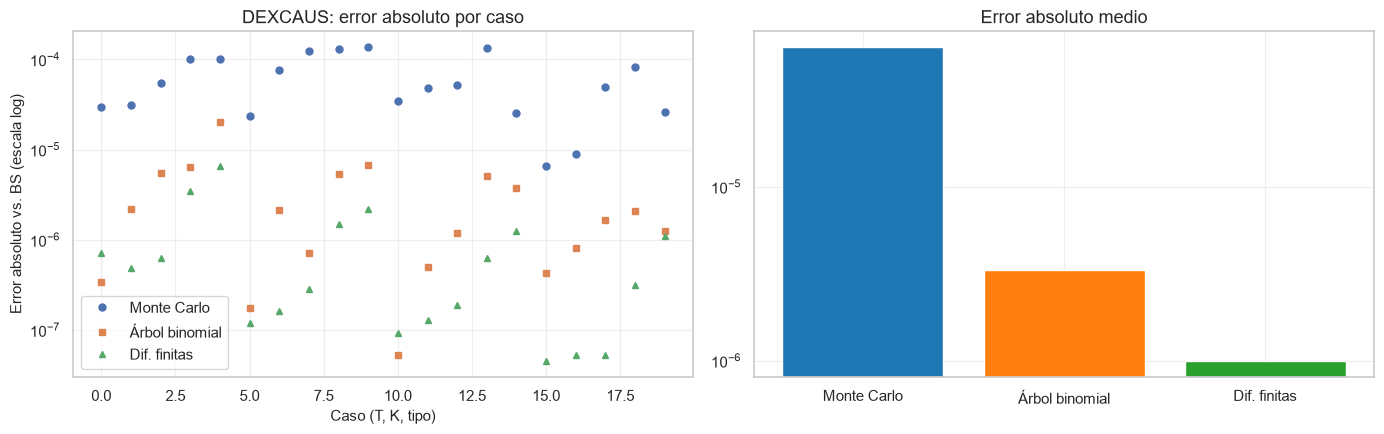

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(opt))
for col, lab, mk in [("|MC−BS|", "Monte Carlo", "o"), ("|Bin−BS|", "Árbol binomial", "s"), ("|DF−BS|", "Dif. finitas", "^")]:
    ax[0].semilogy(x, opt[col].clip(lower=1e-12), mk, label=lab, ms=5)
ax[0].set_xlabel("Caso (T, K, tipo)"); ax[0].set_ylabel("Error absoluto vs. BS (escala log)")
ax[0].set_title(f"{ASSET_NAME}: error absoluto por caso"); ax[0].legend()
ax[1].bar(["Monte Carlo", "Árbol binomial", "Dif. finitas"],
          [opt["|MC−BS|"].mean(), opt["|Bin−BS|"].mean(), opt["|DF−BS|"].mean()],
          color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set_yscale("log"); ax[1].set_title("Error absoluto medio")
plt.tight_layout(); plt.show()

### Convergencia (Call ATM, T = 1)

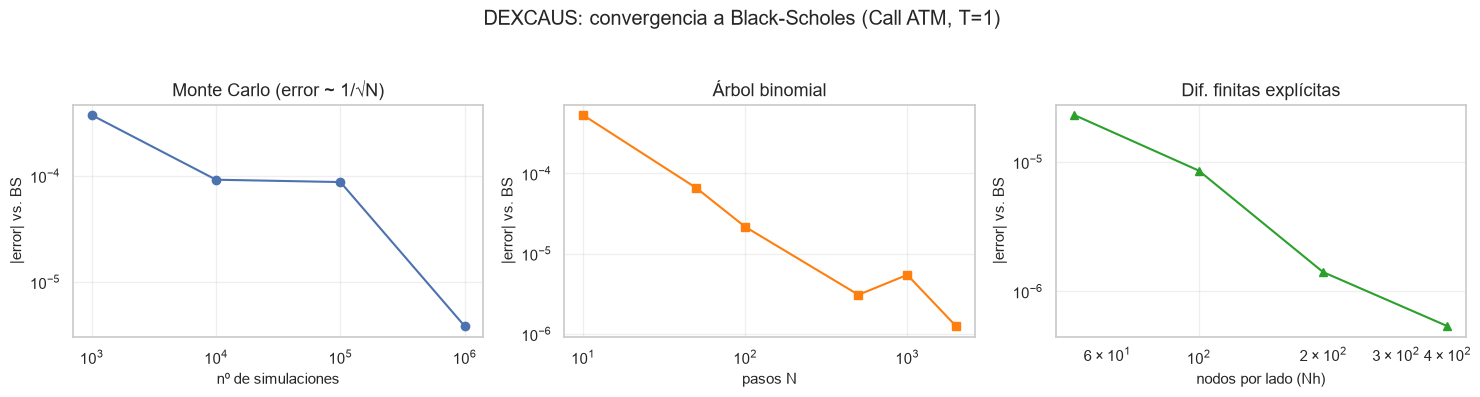

Precio BS de referencia (ATM, T=1, K=1.41) para DEXCAUS: 0.0700


In [61]:
K_atm, T_c = float(strikes[1][2]), 1.0
bs_ref = bs_price(S0_last, K_atm, T_c, r_free, q_yield, sig, "call")
rng_c = np.random.default_rng(99)
Ns_mc  = [10**k for k in (3, 4, 5, 6)]
Ns_bin = [10, 50, 100, 500, 1000, 2000]
Nh_fd  = [50, 100, 200, 400]

err_mc  = [abs(mc_price(S0_last, K_atm, T_c, r_free, q_yield, sig, rng_c.standard_normal(N // 2), "call")[0] - bs_ref) for N in Ns_mc]
err_bin = [abs(binomial_crr(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", N=N) - bs_ref) for N in Ns_bin]
err_fd  = [abs(fd_explicit(S0_last, K_atm, T_c, r_free, q_yield, sig, "call", Nh=h)[0] - bs_ref) for h in Nh_fd]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].loglog(Ns_mc, err_mc, "o-"); ax[0].set_title("Monte Carlo (error ~ 1/√N)"); ax[0].set_xlabel("nº de simulaciones")
ax[1].loglog(Ns_bin, err_bin, "s-", color="tab:orange"); ax[1].set_title("Árbol binomial"); ax[1].set_xlabel("pasos N")
ax[2].loglog(Nh_fd, err_fd, "^-", color="tab:green"); ax[2].set_title("Dif. finitas explícitas"); ax[2].set_xlabel("nodos por lado (Nh)")
for a in ax: a.set_ylabel("|error| vs. BS")
plt.suptitle(f"{ASSET_NAME}: convergencia a Black-Scholes (Call ATM, T=1)", y=1.04)
plt.tight_layout(); plt.show()
print(f"Precio BS de referencia (ATM, T=1, K={K_atm:.2f}) para {ASSET_NAME}: {bs_ref:.4f}")

## 11. Conclusiones cuantitativas

In [62]:
best = summ["Error abs. medio"].idxmin()
print(f"Activo: {ASSET_NAME}")
print(f"Método numérico más cercano a Black-Scholes (menor error absoluto medio): {best}.")
print("• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.")
print("• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.")
print("• Al aumentar K, el precio de la Call disminuye (menor probabilidad de terminar ITM); al aumentar T, la Call se encarece (más valor temporal).")
print("• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.")

Activo: DEXCAUS
Método numérico más cercano a Black-Scholes (menor error absoluto medio): Dif. finitas.
• Black-Scholes es exacto bajo GBM; los demás son aproximaciones numéricas de la misma EDP / esperanza neutral al riesgo.
• Monte Carlo tiene error estadístico (∝ 1/√N); árbol binomial y dif. finitas tienen error de discretización que decrece al refinar la malla.
• Al aumentar K, el precio de la Call disminuye (menor probabilidad de terminar ITM); al aumentar T, la Call se encarece (más valor temporal).
• Estos precios dependen de σ̂ (estimada de la muestra) y de r, q supuestos: la comparación valida los métodos numéricos, no el precio de mercado.


## 12. Notas finales y limitaciones

- **No rechazar H0 no prueba que el supuesto sea cierto**; indica que no hay evidencia en contra con la muestra disponible (~250 observaciones).
- Los precios de la serie y los **strikes se redondearon a 4 decimales** (`PRICE_DECIMALS`, recomendación del profesor), coherente con la escala de la tasa CAD/USD (~1,35–1,43).
- Se usó la **solución exacta del MBG** $S_{t+\Delta t}=S_t\exp[(\mu-\tfrac{\sigma^2}{2})\Delta t+\sigma\sqrt{\Delta t}\,Z]$ (no Euler), tanto para simular como para Monte Carlo.
- Parámetros fijos respetados: $r=0.05$, $S_0=$ último precio, $\sigma=\hat\sigma$, 10.000 simulaciones, $T=\{1,1/2,1/3,1/4\}$, 5 strikes por $T$.
- `q_yield` es un supuesto (0 por defecto, BS clásico). La comparación de métodos numéricos no depende de su valor, pero sí los precios absolutos.
- Este notebook está fijado al conjunto de datos **DEXCAUS** (tasa CAD/USD); los análisis e interpretaciones de los markdowns se refieren a esa serie.
